# Exploring display-ad clicks on Taobao

This notebook explores a real log of display ads shown on Taobao, Alibaba's online shopping site, over 8 days in May 2017.

Three terms we use throughout:

- An **impression** is one ad shown to one user at one moment. Each row of the main table is an impression.
- A **click** means the user clicked that ad.
- The **click-through rate (CTR)** is clicks ÷ impressions. It is the basic performance metric of display advertising, and predicting it is the core machine-learning problem behind ad ranking.

The goal is to understand the data before modelling it: who sees the ads, which ads, where and when, and what is associated with clicks.

**Before you start:** install the packages with `pip install -r requirements.txt`, then run `python download_data.py` from the course folder to get the data (about 1.1 GB).

**Data source:** "Ad Display/Click Data on Taobao.com" by Alibaba, published on [Tianchi](https://tianchi.aliyun.com/dataset/56) under the [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) license. We use three of the original tables, unchanged. The optional user-behaviour log is not included.

## 1. Setup

The full data needs about 6 GB of free memory. On a laptop with 8 GB of RAM or less, set `USER_FRACTION = 0.25` to keep a random quarter of the users with all of their impressions, which needs about 3 GB. The numbers quoted in the text are for the full data, so yours will differ, especially the per-ad statistics: with fewer users, each ad has fewer impressions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../data/taobao")
USER_FRACTION = 1.0

if not DATA_DIR.exists():
    raise FileNotFoundError("Data not found. Run `python download_data.py` from the course folder first.")

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.float_format", "{:,.2f}".format)

mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-klk75kks because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


## 2. The three tables

The data comes as three CSV files linked by IDs:

```text
raw_sample.csv      one row per impression: user, ad, time, placement, click
  ├─ user        →  user_profile.csv   one row per user: gender, age, spending level, ...
  └─ adgroup_id  →  ad_feature.csv     one row per ad: category, brand, advertiser, price, ...
```

Telling pandas the column types when reading (`int32`, `int8`, `category`) uses about a third of the memory that the default types would.

In [2]:
impressions = pd.read_csv(
    DATA_DIR / "raw_sample.csv",
    dtype={"user": "int32", "adgroup_id": "int32", "pid": "category", "nonclk": "int8", "clk": "int8"},
)
ads = pd.read_csv(DATA_DIR / "ad_feature.csv")
users = pd.read_csv(DATA_DIR / "user_profile.csv")

if USER_FRACTION < 1:
    kept_users = impressions["user"].drop_duplicates().sample(frac=USER_FRACTION, random_state=0)
    impressions = impressions[impressions["user"].isin(kept_users)].reset_index(drop=True)

for name, table in {"impressions": impressions, "ads": ads, "users": users}.items():
    print(f"{name:>11}: {len(table):>10,} rows, {table.memory_usage(deep=True).sum() / 1e6:>5,.0f} MB")

impressions: 26,557,961 rows,   505 MB
        ads:    846,811 rows,    41 MB
      users:  1,061,768 rows,    76 MB


In [3]:
impressions.head()

,user,time_stamp,adgroup_id,pid,nonclk,clk
0,581738,1494137644,1,430548_1007,1,0
1,449818,1494638778,3,430548_1007,1,0
2,914836,1494650879,4,430548_1007,1,0
3,914836,1494651029,5,430548_1007,1,0
4,399907,1494302958,8,430548_1007,1,0


In [4]:
ads.head()

,adgroup_id,cate_id,campaign_id,customer,brand,price
0,63133,6406,83237,1,"95,471.00",170.00
1,313401,6406,83237,1,"87,331.00",199.00
2,248909,392,83237,1,"32,233.00",38.00
3,208458,392,83237,1,"174,374.00",139.00
4,110847,7211,135256,2,"145,952.00",32.99


In [5]:
users.head()

,userid,cms_segid,cms_group_id,final_gender_code,age_level,pvalue_level,shopping_level,occupation,new_user_class_level
0,234,0,5,2,5,NaN,3,0,3.00
1,523,5,2,2,2,1.00,3,1,2.00
2,612,0,8,1,2,2.00,3,0,NaN
3,1670,0,4,2,4,NaN,1,0,NaN
4,2545,0,10,1,4,NaN,3,0,NaN


### What the columns mean

These descriptions come from the official documentation. IDs are anonymized numbers, and user attributes are coarse levels rather than exact values.

**Impressions** (`raw_sample.csv`)

| Column | Meaning |
|---|---|
| `user` | User ID |
| `time_stamp` | When the ad was shown, in Unix seconds |
| `adgroup_id` | Ad ID |
| `pid` | Placement where the ad was shown (the documentation calls it "scenario") |
| `clk` | 1 if the user clicked, 0 otherwise |
| `nonclk` | The opposite of `clk` |

**Ads** (`ad_feature.csv`). Each ad promotes one item, and each item has a category and a brand.

| Column | Meaning |
|---|---|
| `adgroup_id` | Ad ID |
| `cate_id` | Item category |
| `campaign_id` | Advertising campaign |
| `customer` | Advertiser |
| `brand` | Item brand |
| `price` | Item price |

**Users** (`user_profile.csv`)

| Column | Meaning |
|---|---|
| `userid` | User ID |
| `cms_segid` | Micro-group ID |
| `cms_group_id` | Group ID |
| `final_gender_code` | Gender: 1 male, 2 female |
| `age_level` | Age bracket, 0 to 6 |
| `pvalue_level` | Spending level: 1 low, 2 medium, 3 high |
| `shopping_level` | Shopping depth: 1 light, 2 moderate, 3 heavy shopper |
| `occupation` | 1 if the user is a college student |
| `new_user_class_level` | City tier, 1 to 4 |

## 3. Data quality checks

Real data almost always has surprises, so we check it before analysing it.

**Column names.** One of them has a hidden trailing space, which would make `users["new_user_class_level"]` fail:

In [6]:
list(users.columns)

['userid',
 'cms_segid',
 'cms_group_id',
 'final_gender_code',
 'age_level',
 'pvalue_level',
 'shopping_level',
 'occupation',
 'new_user_class_level ']

In [7]:
users.columns = users.columns.str.strip()

**Keys.** Each ad and each user should appear only once in their table, and every impression should find its ad and its user.

In [8]:
print("Ad IDs unique:  ", ads["adgroup_id"].is_unique)
print("User IDs unique:", users["userid"].is_unique)
print(f"Impressions whose ad has features:    {impressions['adgroup_id'].isin(ads['adgroup_id']).mean():.1%}")
print(f"Impressions whose user has a profile: {impressions['user'].isin(users['userid']).mean():.1%}")

Ad IDs unique:   True
User IDs unique: True
Impressions whose ad has features:    100.0%


Impressions whose user has a profile: 94.2%


Every impression has ad information, but about 6% come from users without a profile. We keep them and treat their user attributes as missing.

**Labels and duplicates.** `nonclk` should always be the opposite of `clk`, and no impression should appear twice.

In [9]:
print("clk + nonclk == 1 everywhere:", bool((impressions["clk"] + impressions["nonclk"] == 1).all()))
print("Duplicated impressions:", impressions.duplicated(["user", "adgroup_id", "time_stamp"]).sum())
impressions = impressions.drop(columns="nonclk")

clk + nonclk == 1 everywhere: True


Duplicated impressions: 0


Both checks pass, so `nonclk` adds nothing and we drop it.

**Missing values.** Several columns are partly empty:

In [10]:
missing = pd.concat({"ads": ads.isna().mean(), "users": users.isna().mean()})
missing[missing > 0].map("{:.0%}".format)

ads    brand                   29%
users  pvalue_level            54%
       new_user_class_level    32%
dtype: object

The spending level is missing for more than half of the users, the city tier for about a third, and the brand for 29% of the ads. Missing values like these are rarely random (a user may have no spending level because they rarely buy anything), so it is usually better to keep "missing" as a category of its own than to drop those rows.

**Outliers.** Prices look reasonable for most items, but the highest ones are clearly placeholders:

In [11]:
print(ads["price"].describe().round(1).to_string())
print("\nHighest prices:", ads["price"].nlargest(8).tolist())

count      846,811.00
mean         1,838.90
std        310,887.70
min              0.00
25%             49.00
50%            139.00
75%            352.00
max     99,999,999.00

Highest prices: [99999999.0, 99999999.0, 99999999.0, 99999999.0, 99999999.0, 99999999.0, 99999999.0, 88888888.0]


The median item costs 139, but some prices are set to values like 99,999,999 and 88,888,888. An average of raw prices would be dominated by these, so later we compare price buckets instead.

## 4. One table for the analysis

Most questions are easier to answer with one row per impression and all the user and ad attributes next to it. We add them with **left joins**, which keep every impression: impressions from users without a profile get missing user attributes. Converting the attributes to compact types first keeps the joined table small. `Int8` and `Int32` are pandas integer types that allow missing values.

In [12]:
user_columns = [
    "cms_segid", "cms_group_id", "final_gender_code", "age_level",
    "pvalue_level", "shopping_level", "occupation", "new_user_class_level",
]
users = users.astype(dict.fromkeys(user_columns, "Int8"))
ads = ads.astype({"cate_id": "int32", "campaign_id": "int32", "customer": "int32", "brand": "Int32"})

df = (
    impressions
    .merge(users, left_on="user", right_on="userid", how="left")
    .drop(columns="userid")
    .merge(ads, on="adgroup_id", how="left")
)
del impressions
print(f"{len(df):,} rows, {df.shape[1]} columns, {df.memory_usage(deep=True).sum() / 1e9:.1f} GB")
df.head()

26,557,961 rows, 18 columns, 1.6 GB


,user,time_stamp,adgroup_id,pid,clk,cms_segid,cms_group_id,final_gender_code,age_level,pvalue_level,shopping_level,occupation,new_user_class_level,cate_id,campaign_id,customer,brand,price
0,581738,1494137644,1,430548_1007,0,0,8,1,2,<NA>,3,0,<NA>,9025,108570,1337,20169,17.00
1,449818,1494638778,3,430548_1007,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,5998,224368,30507,<NA>,1.00
2,914836,1494650879,4,430548_1007,0,0,5,2,5,<NA>,3,0,2,7958,385883,39662,216840,85.00
3,914836,1494651029,5,430548_1007,0,0,5,2,5,<NA>,3,0,2,7958,385883,39662,216840,60.00
4,399907,1494302958,8,430548_1007,0,0,5,2,5,<NA>,3,0,2,1626,388290,42349,241359,63.00


## 5. Clicks and the click-through rate

In [13]:
overall_ctr = 100 * df["clk"].mean()
print(f"{df['clk'].sum():,} clicks out of {len(df):,} impressions: CTR = {overall_ctr:.2f}%")

1,366,056 clicks out of 26,557,961 impressions: CTR = 5.14%


About 5 impressions in 100 get a click. The two classes are very unbalanced: a model that always predicts "no click" would be right 95% of the time and still be useless. That is why CTR models are judged with metrics such as log loss or AUC rather than accuracy.

Most of the questions below have the same shape: *what is the CTR for each value of some column?* This helper answers it, and we reuse it throughout.

In [14]:
def ctr_by(rows, by):
    """Impressions, clicks and CTR (in %) for each value of `by` (a column name, a list of them, or a Series)."""
    out = rows.groupby(by, observed=True, dropna=False)["clk"].agg(impressions="size", clicks="sum")
    out["ctr_pct"] = 100 * out["clicks"] / out["impressions"]
    return out

## 6. When: day and hour

Timestamps are in Unix seconds. The documentation says `1494032110` means 2017-05-06 08:55:10, which is China time (UTC+8), so we convert to that time zone before extracting the day and the hour.

In [15]:
df["shown_at"] = pd.to_datetime(df["time_stamp"], unit="s", utc=True).dt.tz_convert("Asia/Shanghai")
df = df.drop(columns="time_stamp")
df["day"] = df["shown_at"].dt.day.astype("int8")
df["hour"] = df["shown_at"].dt.hour.astype("int8")
print("From", df["shown_at"].min(), "to", df["shown_at"].max())

From 2017-05-06 00:00:00+08:00 to 2017-05-13 23:59:46+08:00


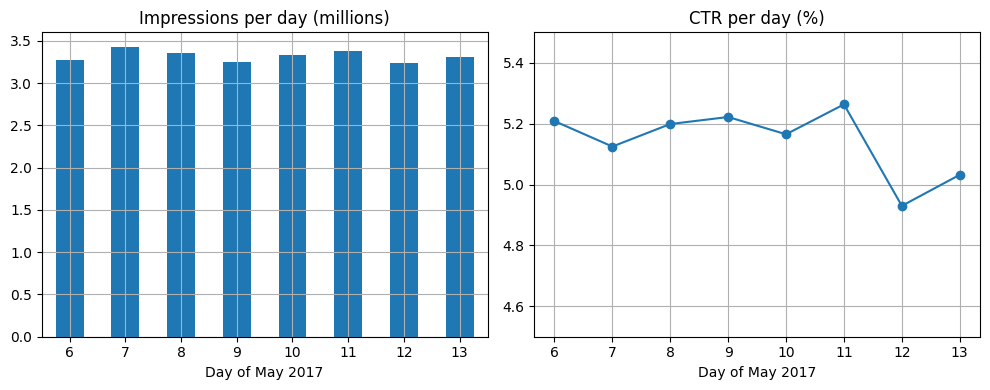

In [16]:
by_day = ctr_by(df, "day")
fig, (left, right) = plt.subplots(1, 2)
(by_day["impressions"] / 1e6).plot.bar(ax=left, rot=0, title="Impressions per day (millions)", xlabel="Day of May 2017")
by_day["ctr_pct"].plot(ax=right, marker="o", ylim=(4.5, 5.5), title="CTR per day (%)", xlabel="Day of May 2017")
plt.tight_layout()
plt.show()

Traffic is steady at about 3.3 million impressions a day, and the CTR stays between 4.9% and 5.3%. The official split uses May 6–12 for training and May 13 for testing (section 10).

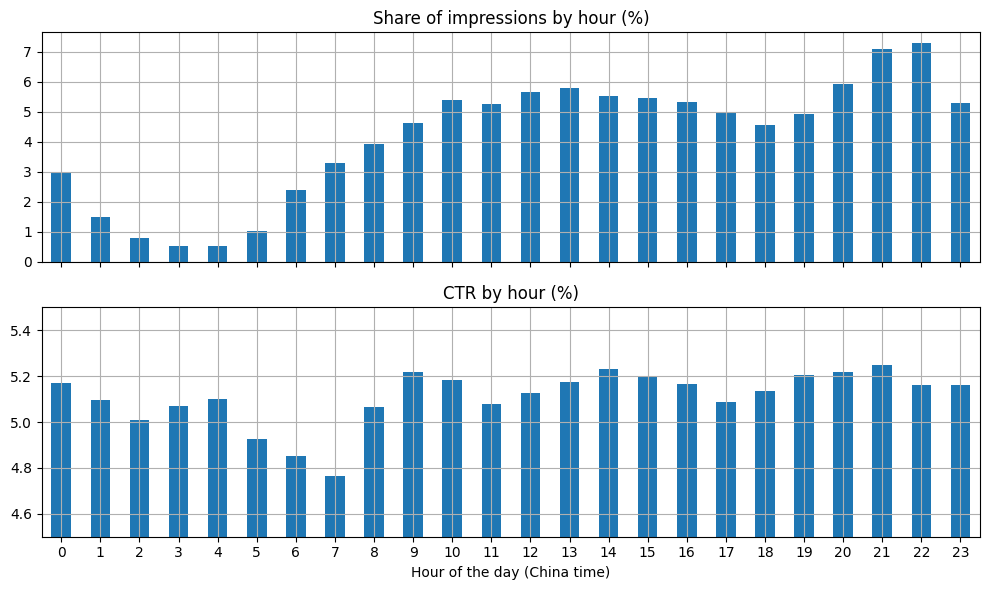

In [17]:
by_hour = ctr_by(df, "hour")
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
(100 * by_hour["impressions"] / by_hour["impressions"].sum()).plot.bar(ax=top, rot=0, title="Share of impressions by hour (%)")
by_hour["ctr_pct"].plot.bar(ax=bottom, rot=0, ylim=(4.5, 5.5), title="CTR by hour (%)", xlabel="Hour of the day (China time)")
plt.tight_layout()
plt.show()

People see the most ads late in the evening (9–11 pm) and the fewest around 3–4 am. The CTR moves much less, from about 4.8% in the early morning to about 5.25% in the evening: the time of day changes how many ads people see far more than whether they click. Note that the CTR axis starts at 4.5%, which makes small differences look big.

## 7. Where: the placement

`pid` tells us where on Taobao the ad was shown. There are only two placements:

In [18]:
ctr_by(df, "pid")

,impressions,clicks,ctr_pct
pid,,,
430539_1007,10085063,540342,5.36
430548_1007,16472898,825714,5.01


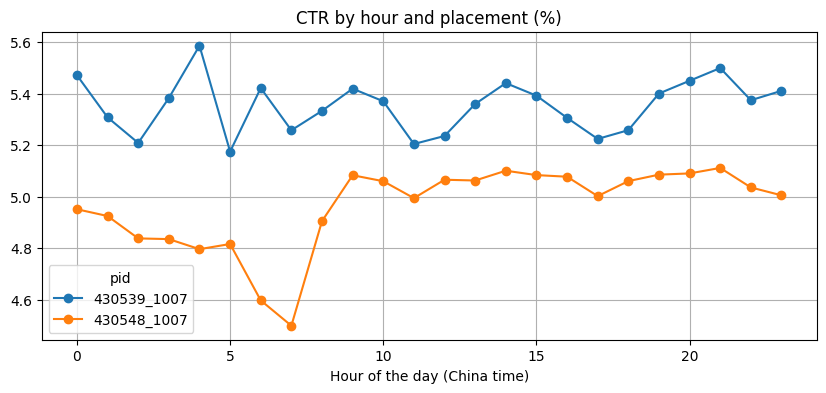

In [19]:
ctr_by(df, ["hour", "pid"])["ctr_pct"].unstack().plot(
    marker="o", title="CTR by hour and placement (%)", xlabel="Hour of the day (China time)"
)
plt.show()

The smaller placement (`430539_1007`, 10 million impressions) has a CTR of 5.36%, against 5.01% for the larger one, and the gap holds at every hour. Where an ad is shown affects how likely it is to be clicked, which is why ad models always include the placement or the position on the page.

## 8. Who: the users

How many ads does each user see?

count   1,141,729.00
mean           23.30
std            65.40
min             1.00
50%             7.00
90%            48.00
99%           286.00
max         3,756.00

Users who never clicked: 57%


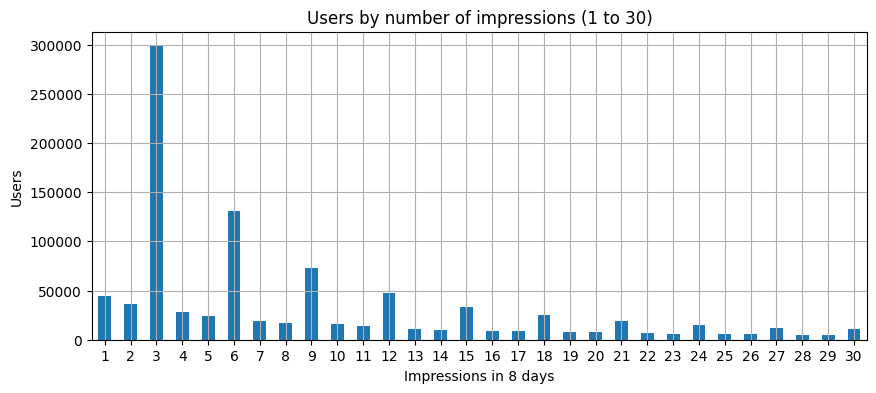

In [20]:
per_user = df.groupby("user")["clk"].agg(impressions="size", clicks="sum")
print(per_user["impressions"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())
print(f"\nUsers who never clicked: {(per_user['clicks'] == 0).mean():.0%}")

ax = per_user["impressions"].value_counts().sort_index().loc[1:30].plot.bar(
    rot=0, title="Users by number of impressions (1 to 30)", xlabel="Impressions in 8 days"
)
ax.set_ylabel("Users")
plt.show()

The typical user saw 7 ads in 8 days, but a few saw thousands (the maximum is 3,756). Long tails like this are normal in ads data: a small group of very active users, and possibly some bots, generates a large share of the traffic. More than half of the users (57%) never clicked at all.

The chart also has a surprise: spikes at 3, 6, 9, 12 and 15 impressions. Let's check how many ads each user was shown in the same second:

In [21]:
same_moment = df.groupby(["user", "shown_at"]).size()
print("Number of ads shown to the same user in the same second:")
print(same_moment.value_counts().sort_index().head(6).to_string())
print(f"\nShare of impressions shown in blocks of exactly three: {3 * (same_moment == 3).sum() / len(df):.0%}")

Number of ads shown to the same user in the same second:
1     352293
2     326311
3    4644411
4      45456
5      40271
6      39500

Share of impressions shown in blocks of exactly three: 52%


Ads are usually shown **three at a time**: about half of all impressions come in blocks of three ads shown to the same user in the same second, which explains the spikes. So an impression is often one of three ads on the same screen, competing for the same attention, which is worth remembering when we model clicks.

Do some kinds of users click more? In the charts below, the dashed line is the overall CTR, and the bar labelled `<NA>` groups users whose attribute is missing.

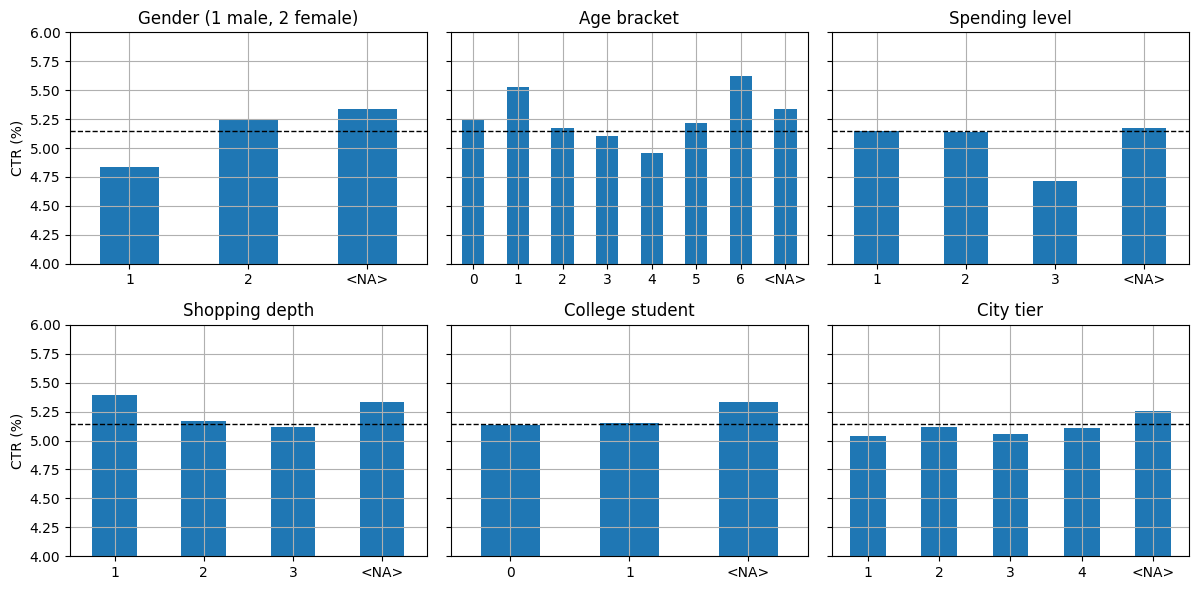

In [22]:
user_attributes = {
    "final_gender_code": "Gender (1 male, 2 female)",
    "age_level": "Age bracket",
    "pvalue_level": "Spending level",
    "shopping_level": "Shopping depth",
    "occupation": "College student",
    "new_user_class_level": "City tier",
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for (column, title), ax in zip(user_attributes.items(), axes.flat):
    ctr_by(df, column)["ctr_pct"].plot.bar(ax=ax, rot=0, ylim=(4, 6), title=title, xlabel="")
    ax.axhline(overall_ctr, color="black", linestyle="--", linewidth=1)
for ax in axes[:, 0]:
    ax.set_ylabel("CTR (%)")
plt.tight_layout()
plt.show()

Each attribute on its own moves the CTR by at most about half a percentage point:

- Women click more than men (5.24% against 4.84%), and they receive 72% of the impressions from users with a profile.
- The youngest and oldest age brackets (1 and 6) click the most, at about 5.5–5.6%.
- High spenders click the least (4.72%).
- Light shoppers click a little more than heavy shoppers (5.40% against 5.11%).
- College students click like everyone else.

Weak signals like these are typical. CTR models get their accuracy by combining many weak signals and their interactions, not from any single column.

## 9. What: the ads

The 846,811 ads belong to 423,436 campaigns from 255,875 advertisers, and promote items in 6,769 categories. How often is each ad shown?

In [23]:
per_ad = df.groupby("adgroup_id")["clk"].agg(impressions="size", clicks="sum")
per_ad["ctr_pct"] = 100 * per_ad["clicks"] / per_ad["impressions"]
print(per_ad["impressions"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())
print(f"\nAds shown only once:          {(per_ad['impressions'] == 1).mean():.0%}")
print(f"Ads shown fewer than 10 times: {(per_ad['impressions'] < 10).mean():.0%}")

count   846,811.00
mean         31.40
std         200.40
min           1.00
50%           4.00
90%          56.00
99%         452.00
max      70,929.00

Ads shown only once:          30%
Ads shown fewer than 10 times: 68%


Ads have an even longer tail than users: the median ad was shown 4 times, 30% were shown only once, and the most frequent one 70,929 times.

### The small-numbers problem

Which ads have the highest CTR? Sorting by the raw CTR gives a misleading answer:

In [24]:
perfect = per_ad[per_ad["ctr_pct"] == 100]
print(f"Ads with a 100% CTR: {len(perfect):,}, none with more than {perfect['impressions'].max()} impressions")
per_ad.sort_values("ctr_pct", ascending=False).head(10)

Ads with a 100% CTR: 7,574, none with more than 3 impressions


,impressions,clicks,ctr_pct
adgroup_id,,,
604379,1,1,100.00
549099,1,1,100.00
111567,1,1,100.00
441788,1,1,100.00
441819,1,1,100.00
771721,1,1,100.00
549095,1,1,100.00
79130,1,1,100.00
208477,1,1,100.00


The top of the list is all ads that were shown once or twice and happened to be clicked. The plot shows the same effect across all ads: the fewer impressions an ad has, the more extreme its CTR can be.

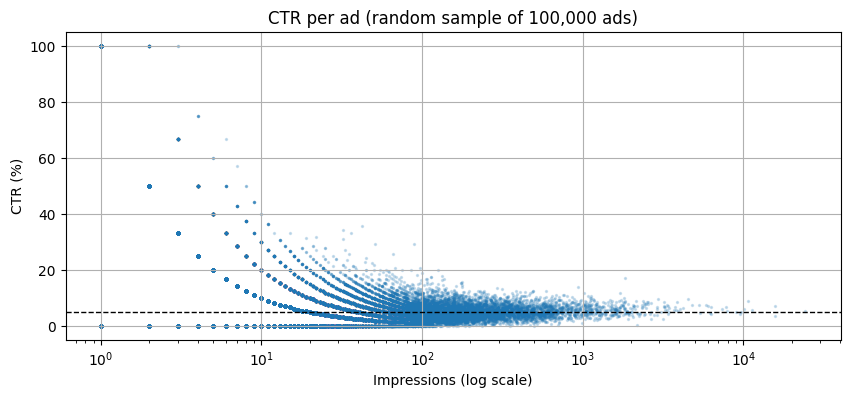

In [25]:
sample = per_ad.sample(min(100_000, len(per_ad)), random_state=0)
ax = sample.plot.scatter(x="impressions", y="ctr_pct", s=2, alpha=0.2, title="CTR per ad (random sample of 100,000 ads)")
ax.set_xscale("log")
ax.axhline(overall_ctr, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Impressions (log scale)")
ax.set_ylabel("CTR (%)")
plt.show()

A common fix is **smoothing**: before computing an ad's CTR, pretend it already had some impressions at the average CTR. Here we add 100 of these "virtual" impressions. Ads with few impressions are pulled towards the average, while ads with many impressions keep roughly their own CTR.

In [26]:
prior_impressions = 100
per_ad["smoothed_ctr_pct"] = (
    100 * (per_ad["clicks"] + prior_impressions * overall_ctr / 100) / (per_ad["impressions"] + prior_impressions)
)
per_ad.sort_values("smoothed_ctr_pct", ascending=False).head(10)

,impressions,clicks,ctr_pct,smoothed_ctr_pct
adgroup_id,,,,
606227,127,39,30.71,19.45
780126,2511,499,19.87,19.31
673600,222,51,22.97,17.44
749687,10098,1756,17.39,17.27
700651,2147,381,17.75,17.18
380921,100,28,28.00,16.57
512989,428,82,19.16,16.50
267535,89,26,29.21,16.48
792889,1835,313,17.06,16.44


Now the top of the list is made of ads with between about 90 and 10,000 impressions and CTRs of 16–31%, which is much more believable. The same problem, and the same fix, applies to any CTR computed per user, advertiser, brand or category.

### Price

To avoid the placeholder prices, we split the impressions into ten equal-sized price buckets (deciles), from 1 for the cheapest 10% of impressions to 10 for the most expensive, and compare their CTR.

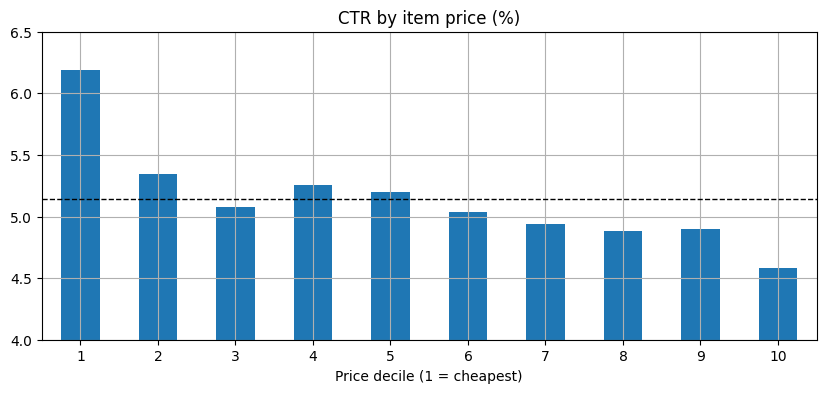

,impressions,clicks,ctr_pct,min_price,max_price
price_decile,,,,,
1,2669796,165160,6.19,0.01,35.00
2,2727332,145706,5.34,35.05,68.00
3,2578309,130910,5.08,68.01,98.00
4,2675041,140497,5.25,98.03,128.00
5,3028616,157360,5.20,128.01,168.00
6,2374177,119616,5.04,168.10,199.00
7,2591415,127920,4.94,199.01,288.00
8,2817875,137677,4.89,288.01,398.00
9,2443501,119716,4.90,398.10,689.00


In [27]:
price_decile = (pd.qcut(df["price"], 10, labels=False, duplicates="drop") + 1).rename("price_decile")
by_price = ctr_by(df, price_decile).join(df.groupby(price_decile)["price"].agg(min_price="min", max_price="max"))
ax = by_price["ctr_pct"].plot.bar(rot=0, ylim=(4, 6.5), title="CTR by item price (%)", xlabel="Price decile (1 = cheapest)")
ax.axhline(overall_ctr, color="black", linestyle="--", linewidth=1)
plt.show()
by_price

Cheaper items get more clicks: about 6.2% for items costing up to 35, falling to about 4.6% for items above 689. The placeholder prices simply end up in the top bucket.

### Categories

A few categories get most of the impressions:

In [28]:
by_category = ctr_by(df, "cate_id").sort_values("impressions", ascending=False)
top10_share = by_category["impressions"].head(10).sum() / by_category["impressions"].sum()
print(f"{len(by_category):,} categories; the top 10 get {top10_share:.0%} of the impressions")
by_category.head(10)

6,769 categories; the top 10 get 39% of the impressions


,impressions,clicks,ctr_pct
cate_id,,,
6261,2925127,180302,6.16
1665,1535282,86534,5.64
4520,1135981,54120,4.76
4282,962743,51753,5.38
4281,958857,54384,5.67
6426,778601,38433,4.94
4284,554017,31473,5.68
4280,535389,29586,5.53
4283,484225,25511,5.27


The top 10 of the 6,769 categories receive 39% of all impressions, and their CTRs range from about 4.8% to 6.2%. We only know category IDs, not names, but we can still compare categories and use them as model inputs.

### Missing brand

Does it tell us anything that an ad has no brand?

In [29]:
ctr_by(df, df["brand"].isna().rename("brand_missing"))

,impressions,clicks,ctr_pct
brand_missing,,,
False,18266267,908731,4.97
True,8291694,457325,5.52


Ads without a brand get 31% of the impressions and a higher CTR (5.52% against 4.97%). Here "missing" carries information, which is why we keep missing values as a category of their own instead of dropping them.

## 10. Training and test days

The official split trains models on May 6–12 and tests them on May 13. Splitting by time rather than at random mimics real use, where a model is trained on the past and used on the future. One consequence is that the test day contains ads and users that the model has never seen.

In [30]:
is_test = df["day"] == 13
print(f"Training impressions: {(~is_test).sum():,}; test impressions: {is_test.sum():,}")
for column, label in [("adgroup_id", "ads"), ("user", "users")]:
    test = df.loc[is_test, [column, "clk"]]
    seen = test[column].isin(df.loc[~is_test, column].unique())
    print(
        f"Test impressions with {label} never seen in training: {1 - seen.mean():.1%} "
        f"(CTR {100 * test.loc[~seen, 'clk'].mean():.2f}%, against {100 * test.loc[seen, 'clk'].mean():.2f}% for the others)"
    )

Training impressions: 23,249,296; test impressions: 3,308,665


Test impressions with ads never seen in training: 2.8% (CTR 3.03%, against 5.09% for the others)


Test impressions with users never seen in training: 9.4% (CTR 5.95%, against 4.94% for the others)


About 2.8% of the test impressions are for ads that never appeared in training, and those get far fewer clicks (3.0% against 5.1%). About 9.4% come from users not seen in training, and they click more (5.9% against 4.9%). Handling these "cold-start" ads and users is a key design question for any ad model.

## 11. Summary

- 26.6 million impressions from 1.14 million users and about 850,000 ads over 8 days, with a CTR of 5.1%.
- The data needed a few fixes: a column name with a trailing space, a redundant label column, missing values (kept as their own category) and placeholder prices.
- Traffic follows a daily cycle and peaks in the evening, while the CTR changes little over the day.
- Ads are usually shown in blocks of three, to the same user at the same moment.
- Placement, item price, a missing brand and some user attributes are associated with the CTR, but each signal on its own is weak.
- Users and especially ads have very long tails. Most ads have only a handful of impressions, so per-ad CTRs need smoothing.
- New ads on the test day are clicked much less, which is one reason to split by time.

## Exercises

1. `cms_group_id` has a wider CTR range than any of the user attributes above. Use `pd.crosstab(users["cms_group_id"], [users["final_gender_code"], users["age_level"]])` to find out what it encodes.
2. Section 7 showed that the placement gap holds at every hour. Does it also hold on every day?
3. In the blocks of three ads shown together (section 8), how often is more than one of the three clicked? Are the three ads always in the same placement?
4. Compute a smoothed CTR per advertiser (`customer`). How many advertisers have at least 1,000 impressions?
5. Which columns would you use as inputs to a model that predicts clicks on May 13? Could any of them leak the answer?
6. A first baseline model: for each test impression, predict the training CTR of its placement. Is its log loss (`sklearn.metrics.log_loss`) better than always predicting the overall training CTR?